In [4]:
#from google.colab import drive
import os
import torch
from itertools import combinations
import numpy as np
from scipy.stats import chi2
import matplotlib.pyplot as plt
import torchvision

from src.data import image_hash_groups

from src.build import build_model

In [3]:
drive.mount('/content/drive')
%cd /content/drive/MyDrive/assignments/Vision_Transformers
!git pull
%pip install -q -r requirements.txt
with open("/content/drive/MyDrive/credentials/wandb_api.txt") as f:
    os.environ["WANDB_API_KEY"] = f.read().strip()
    print("W&B key loaded:", len(os.environ.get("WANDB_API_KEY", "")) > 0)
# Check for PyTorch and CUDA availability
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
!pip freeze | grep -E "torch|numpy|scikit|wandb"
!pip freeze | grep -iE "^(pytest|pandas|matplotlib|tqdm|pylint)=="
!python --version

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/assignments/Vision_Transformers
Already up to date.
W&B key loaded: True
PyTorch version: 2.11.0+cu130
CUDA available: True
numpy==2.4.6
scikit-image==0.25.2
scikit-learn==1.6.1
torch==2.11.0
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.17.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.26.0
wandb==0.28.1
matplotlib==3.10.0
pandas==2.2.3
pylint==4.1.3
pytest==8.4.2
tqdm==4.67.3
Python 3.13.16


## Duplicate Training Set Images

14 duplicate groups, 49986 unique images
[4348, 30931] ['aquarium_fish', 'aquarium_fish']
[8393, 36874] ['girl', 'baby']
[8599, 22657] ['aquarium_fish', 'aquarium_fish']
[9012, 31128] ['otter', 'seal']
[16646, 31828] ['mouse', 'shrew']
[17688, 41874] ['seal', 'otter']
[18461, 46752] ['snake', 'worm']
[20635, 32666] ['aquarium_fish', 'aquarium_fish']
[23947, 33638] ['seal', 'otter']
[25218, 46851] ['aquarium_fish', 'aquarium_fish']
[27737, 47636] ['snake', 'worm']
[28293, 41860] ['aquarium_fish', 'aquarium_fish']
[30418, 47806] ['spider', 'crab']
[31227, 34187] ['whale', 'shark']


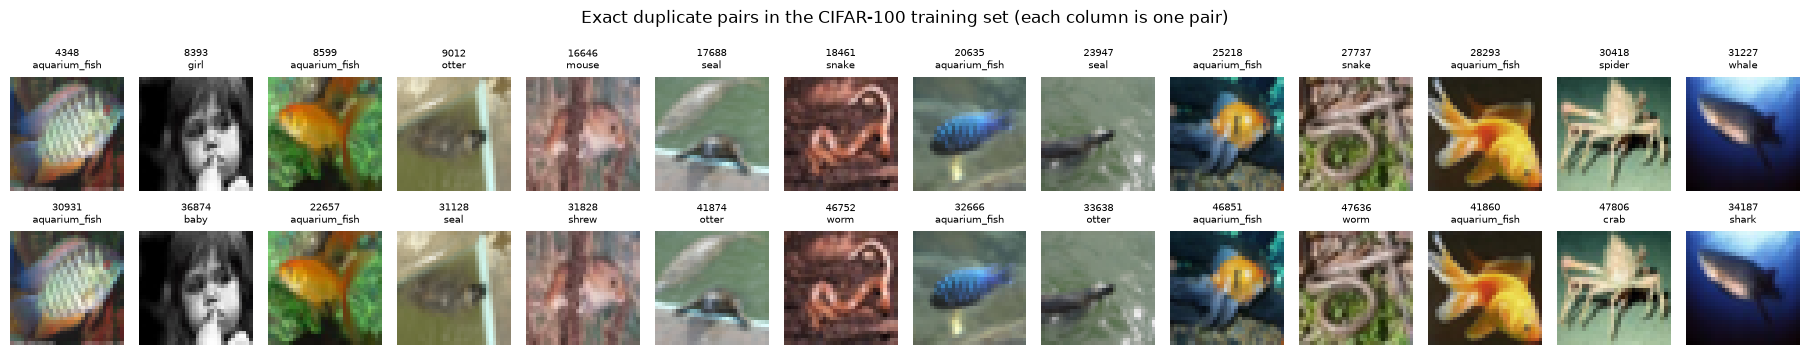

In [6]:
train_set = torchvision.datasets.CIFAR100(root="data", train=True, download=False)

# Groups of training images with identical pixels
groups = image_hash_groups(train_set.data)
duplicates = [indices for indices in groups.values() if len(indices) > 1]
n_unique = len(train_set.data) - sum(len(indices) - 1 for indices in duplicates)
print(f"{len(duplicates)} duplicate groups, {n_unique} unique images")
for indices in duplicates:
    print(indices, [train_set.classes[train_set.targets[i]] for i in indices])

# One column per pair; each image is titled with its index and label
fig, axes = plt.subplots(2, len(duplicates), figsize=(1.3 * len(duplicates), 3.8))
for col, indices in enumerate(duplicates):
    for row, idx in enumerate(indices[:2]):
        axes[row, col].imshow(train_set.data[idx])
        axes[row, col].set_title(f"{idx}\n{train_set.classes[train_set.targets[idx]]}", fontsize=7)
        axes[row, col].axis("off")
fig.suptitle("Exact duplicate pairs in the CIFAR-100 training set (each column is one pair)")
fig.tight_layout()
plt.show()

## Model Parameters

In [ ]:
models = {
    "Plain ViT": {"arch": "vit", "tokenizer": "patch", "depth": 9, "drop_path_rate": 0.1},
    "Hybrid": {"arch": "vit", "tokenizer": "resnet", "depth": 7, "drop_path_rate": 0.1},
    "Swin": {"arch": "swin", "drop_path_rate": 0.1},
}

for name, settings in models.items():
    model = build_model(settings)
    total_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
    print(f"{name}: {total_parameters:,}")

Plain ViT: 4,799,076
Hybrid: 4,604,084
Swin: 4,247,064


## McNemar Test and Bonferri Correction

In [3]:
runs = {"Hybrid": "hybrid_seed2026", "Plain ViT": "vit_seed2026", "Swin": "swin_seed2026"}

# Which test images each model got right
correct = {}
labels = None
for name, run in runs.items():
    preds_file = np.load(f"logs/{run}_test_preds.npz")
    if labels is None:
        labels = preds_file["labels"]
    assert np.array_equal(preds_file["labels"], labels), f"{run}: labels differ"
    correct[name] = preds_file["preds"] == labels

pairs = list(combinations(runs, 2))
print(f"{'Pair':<20}{'b':>6}{'c':>6}{'chi2':>9}{'p':>12}{'Bonferroni p':>15}")
for model_a, model_b in pairs:
    # b: A right and B wrong; c: B right and A wrong
    b = np.sum(correct[model_a] & ~correct[model_b])
    c = np.sum(~correct[model_a] & correct[model_b])
    stat = (abs(b - c) - 1) ** 2 / (b + c)  # continuity correction
    p = chi2.sf(stat, df=1)
    p_adjusted = min(1.0, len(pairs) * p)
    print(f"{model_a + ' vs ' + model_b:<20}{b:>6}{c:>6}{stat:>9.1f}{p:>12.3g}{p_adjusted:>15.3g}")

Pair                     b     c     chi2           p   Bonferroni p
Hybrid vs Plain ViT   1127   621    145.9    1.37e-33       4.11e-33
Hybrid vs Swin        1176   592    192.2    1.03e-43       3.09e-43
Plain ViT vs Swin      758   680      4.1      0.0423          0.127
